# Ile komunikacji potrzebuje klaster — model i deficyt 2031/2036

**Pytanie:** ile kursów autobusów i tramwajów *powinien* mieć klaster, biorąc pod uwagę, kto w nim mieszka, pracuje i co się w nim znajduje — i jak to się zmieni, gdy przybędzie mieszkańców i otworzą się nowe stacje metra.

**Pomysł:**
1. Uczymy model na **dzisiejszej** sieci: liczba kursów ZTM w klastrze ≈ f(mieszkańcy, miejsca pracy, szkoły, odległość od centrum, metro…).
2. Model mówi, ile kursów dostaje dziś *typowy* klaster o takich cechach — to „potrzeba” wg obecnych standardów ZTM.
3. Wstawiamy cechy z **2031 i 2036** (prognozowana ludność) i uwzględniamy nowe stacje M2/M3 → **wzrost potrzeby kursów** w każdym klastrze.

> Zastrzeżenie: model uczy się z obecnej sieci, więc mierzy potrzebę *przy dzisiejszych standardach ZTM* — nie wie, czy te standardy są dobre.

Dane: `dane/cechy_klastrow.csv` (z `mapping/cechy_klastrow.py`).

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error

INK2, MUTED, GRID, SURF = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})
fmt = lambda x: f"{x:,.0f}".replace(",", " ")

c = pd.read_csv("dane/cechy_klastrow.csv")
print(c.shape)
c.head(3)

(848, 37)


,h3,dzielnica,population,gestosc_os_km2,pow_km2,kursy_dzien_autobus,kursy_dzien_kolej,kursy_dzien_metro,kursy_dzien_tramwaj,kursy_szczyt_bus_tram,...,korek,infra_handel,infra_kult,infra_kultura,infra_park,infra_szkola,infra_szpital,infra_targowisko,infra_urzad,odl_centrum_km
0,881f53d9ebfffff,Białołęka,218,332.0,0.6557,74.0,0.0,0.0,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.26
1,881f53d9e3fffff,Białołęka,75,165.0,0.4551,0.0,0.0,0.0,0.0,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.44
2,881f53d9ddfffff,Białołęka,314,504.0,0.6225,0.0,0.0,0.0,0.0,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.16


## 1. Zmienne

**Cel (y):** `kursy_dzien_bus_tram` — różne kursy autobusów i tramwajów zatrzymujące się w klastrze w dzień roboczy (centrum: tysiące, peryferie: kilkadziesiąt).

**Cechy (X):** tylko to, co opisuje *popyt* i położenie. Pomijamy kolumny, które opisują samą podaż (liczba linii i przystanków, prędkość autobusów) — model by je po prostu przepisał.
Wartości bardzo skośne (mieszkańcy, metry biur, punkty usług) logarytmujemy. Gęstość pomijamy — to mieszkańcy / powierzchnia, a obie te cechy już są (inaczej model liniowy „rozjeżdża” się na dwóch prawie tych samych zmiennych).

In [2]:
TARGET = "kursy_dzien_bus_tram"
LOG_FEATS = ["population", "praca_biura_uslugi_m2", "praca_przemysl_m2", "punkty_uslug"]
FEATS = LOG_FEATS + ["udzial_0_14", "udzial_65_", "odl_centrum_km", "dist_metro_m", "dist_kolej_m", "pow_km2",
                     "infra_szkola", "infra_szpital", "infra_handel", "infra_kultura", "infra_urzad", "infra_targowisko", "infra_park"]

def design(df):
    X = df[FEATS].copy()
    X[LOG_FEATS] = np.log1p(X[LOG_FEATS].clip(lower=0))
    X["dist_metro_m"] = np.log1p(X["dist_metro_m"])        # 200 m vs 2 km od metra to duża różnica, 8 vs 10 km — mała
    X["dist_kolej_m"] = np.log1p(X["dist_kolej_m"])
    return X.fillna({"udzial_0_14": c["udzial_0_14"].median(), "udzial_65_": c["udzial_65_"].median()})

X, y = design(c), c[TARGET]
groups = c["dzielnica"]
print(f"{len(FEATS)} cech, {len(c)} klastrów; kursy/dobę: mediana {c[TARGET].median():.0f}, maks. {c[TARGET].max():.0f}")

17 cech, 848 klastrów; kursy/dobę: mediana 270, maks. 4952


## 2. Dwa modele i uczciwy test

Test **po dzielnicach** (`GroupKFold`): model uczy się na 17 dzielnicach i przewiduje 18. — tak jakby oceniał dzielnicę, której nie widział. Zwykły losowy podział zawyżyłby wynik, bo sąsiednie klastry są do siebie podobne.

* **Ridge (log)** — regresja liniowa na log(kursów): prosta do wytłumaczenia, punkt odniesienia.
* **Gradient boosting (log)** — drzewa decyzyjne na log(kursów).
* **Gradient boosting (kursy, monotoniczny)** — drzewa na liczbie kursów z warunkiem, że **więcej mieszkańców, biur i usług nigdy nie zmniejsza potrzeby** — dzięki temu prognoza na 2036 zachowuje się sensownie.

Wybieramy model po błędzie w **liczbie kursów** (to nas interesuje), nie w logarytmie.

In [3]:
GB = dict(max_iter=500, learning_rate=0.04, max_leaf_nodes=15, min_samples_leaf=15, l2_regularization=1.0, random_state=0)
MONO = {"population": 1, "praca_biura_uslugi_m2": 1, "punkty_uslug": 1}
models = {   # nazwa -> (model, czy uczy się na log(kursów))
    "Ridge (log)": (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))), True),
    "Gradient boosting (log)": (HistGradientBoostingRegressor(**GB), True),
    "Gradient boosting (kursy, monotoniczny)": (HistGradientBoostingRegressor(**GB, monotonic_cst=[MONO.get(f, 0) for f in FEATS]), False),
}
cv = GroupKFold(n_splits=6)
res, preds = [], {}
for name, (m, use_log) in models.items():
    p = cross_val_predict(m, X, np.log1p(y) if use_log else y, cv=cv, groups=groups)
    p = np.expm1(p) if use_log else np.clip(p, 0, None)
    preds[name] = p
    res.append({"model": name, "R² (kursy)": r2_score(y, p), "MAE [kursów/dobę]": mean_absolute_error(y, p)})
pd.DataFrame(res).set_index("model").round(3)

,R² (kursy),MAE [kursów/dobę]
model,,
Ridge (log),0.191,367.720
Gradient boosting (log),0.447,343.340
"Gradient boosting (kursy, monotoniczny)",0.598,306.447


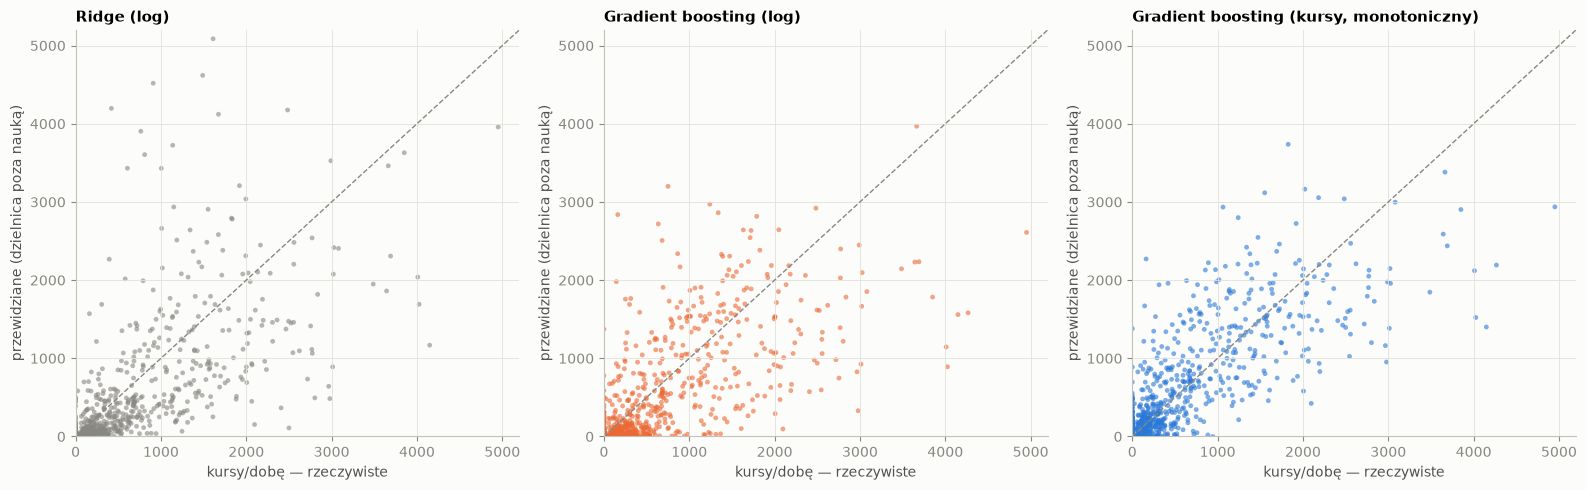

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, p), color in zip(axes, preds.items(), [MUTED, ORANGE, BLUE]):
    ax.scatter(c[TARGET], p, s=12, color=color, alpha=0.6, edgecolor="none")
    lim = [0, c[TARGET].max() * 1.05]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(name, fontsize=11); ax.set_xlabel("kursy/dobę — rzeczywiste"); ax.set_ylabel("przewidziane (dzielnica poza nauką)")
plt.tight_layout(); plt.show()

## 3. Co decyduje o liczbie kursów

**Ważność cech** (permutacyjna): o ile pogarsza się model, gdy losowo pomieszamy daną cechę. Liczona na najlepszym modelu dopasowanym do wszystkich danych.

model końcowy: Gradient boosting (kursy, monotoniczny)


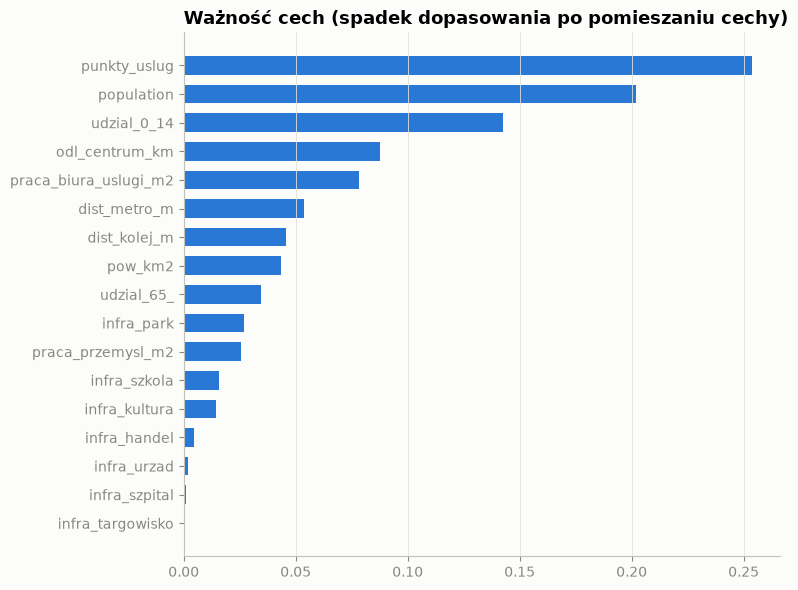

In [5]:
best_name = min(res, key=lambda r: r["MAE [kursów/dobę]"])["model"]
final, final_log = models[best_name]
final.fit(X, np.log1p(y) if final_log else y)
predict = lambda XX: np.expm1(final.predict(XX)) if final_log else np.clip(final.predict(XX), 0, None)
print("model końcowy:", best_name)
imp = permutation_importance(final, X, np.log1p(y) if final_log else y, n_repeats=10, random_state=0)
imp = pd.Series(imp.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color=BLUE, height=0.65)
ax.set_title("Ważność cech (spadek dopasowania po pomieszaniu cechy)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [6]:
# Kierunek wpływu z modelu liniowego (cechy wystandaryzowane: +1 odch. std. cechy -> zmiana log(kursów))
ridge = models["Ridge (log)"][0].fit(X, np.log1p(y))
coef = pd.Series(ridge[-1].coef_, index=FEATS).sort_values()
pd.DataFrame({"wpływ (log kursów na 1 odch. std.)": coef.round(3),
              "≈ zmiana kursów [%]": ((np.exp(coef) - 1) * 100).round(0)})

,wpływ (log kursów na 1 odch. std.),≈ zmiana kursów [%]
pow_km2,-0.115,-11.0
infra_park,-0.097,-9.0
odl_centrum_km,-0.052,-5.0
infra_kultura,-0.030,-3.0
udzial_0_14,-0.029,-3.0
infra_szpital,-0.023,-2.0
infra_targowisko,-0.014,-1.0
infra_handel,-0.004,-0.0
praca_przemysl_m2,0.026,3.0
infra_urzad,0.035,4.0


## 4. Dziś: kto jest obsługiwany lepiej, a kto gorzej niż „typowo”

`potrzeba_dzis` = przewidywana liczba kursów dla klastra o takich cechach (wynik testu po dzielnicach, więc model nie widział tego klastra).
Ujemna różnica (`obsluga − potrzeba`) = klaster dostaje mniej kursów niż podobne klastry w innych dzielnicach.

In [7]:
c["potrzeba_dzis"] = preds[best_name].round(0)
c["roznica_dzis"] = (c[TARGET] - c["potrzeba_dzis"]).round(0)
zamieszkale = c[c["population"] > 1000]
print("Najbardziej niedoobsłużone dziś (zamieszkałe > 1000 os.):")
display(zamieszkale.nsmallest(10, "roznica_dzis")[["h3", "dzielnica", "population", TARGET, "potrzeba_dzis", "roznica_dzis", "dist_metro_m"]])

Najbardziej niedoobsłużone dziś (zamieszkałe > 1000 os.):


,h3,dzielnica,population,kursy_dzien_bus_tram,potrzeba_dzis,roznica_dzis,dist_metro_m
211,881f53c999fffff,Praga-Południe,9391,162.0,2270.0,-2108.0,4623
268,881f53c907fffff,Wola,6032,1827.0,3737.0,-1910.0,299
257,881f53c921fffff,Wola,2957,1063.0,2934.0,-1871.0,1102
177,881f53c9e7fffff,Śródmieście,2114,314.0,1941.0,-1627.0,1554
230,881f53c95dfffff,Żoliborz,6404,1552.0,3117.0,-1565.0,499
263,881f53c913fffff,Śródmieście,3363,1241.0,2799.0,-1558.0,286
723,881f52249bfffff,Ursynów,10840,419.0,1960.0,-1541.0,269
616,881f5226c3fffff,Mokotów,3340,0.0,1380.0,-1380.0,1206
104,881f53cb29fffff,Bielany,7206,636.0,1994.0,-1358.0,321
343,881f53c82bfffff,Praga-Północ,6836,892.0,2223.0,-1331.0,156


## 5. Rok 2031 i 2036: przyszła potrzeba i deficyt

Zmieniamy w cechach to, co prognozujemy:
* **mieszkańcy** — z `prognoza_ludnosci.csv` (`pop_2031`, `pop_2036`); reszta (praca, szkoły, usługi) zostaje jak dziś.

**Nowe metro — jawne założenie.** Z dzisiejszej sieci model nie nauczy się, że metro *zastępuje* autobusy: blisko metra jest centrum, które ma najwięcej kursów (odległość do metra prawie nic nie dodaje do modelu). Dlatego efekt nowych stacji dokładamy osobno: w promieniu `METRO_R` m od stacji otwartej do roku t potrzeba autobusów i tramwajów spada o `METRO_SUBST` (domyślnie 25%). Parametry poniżej — łatwo zmienić.

**Deficyt = potrzeba w roku t − dzisiejsza liczba kursów.** Dodatni = trzeba będzie dołożyć kursy.

In [8]:
hexes = gpd.read_file("dane/kontury_400m/warszawa_h3_400m_pelna.geojson")[["h3", "geometry"]]
cent = hexes.set_index("h3").to_crs(2180).centroid.reindex(c["h3"]).values

dane_app = json.load(open("frontend/symulator_dane.json", encoding="utf-8"))
planned = [(lon, lat, rok) for m in dane_app["planned_metro"] for lon, lat, name, ex in m["stacje"] if not ex for rok in [m["rok"]]]
pl = gpd.GeoDataFrame({"rok": [p[2] for p in planned]}, geometry=gpd.points_from_xy([p[0] for p in planned], [p[1] for p in planned]), crs=4326).to_crs(2180)

METRO_R, METRO_SUBST = 800, 0.25

def features_for(year):
    f = c.copy()
    f["population"] = c[f"pop_{year}"]
    return design(f)

def metro_factor(year):
    new = pl[pl["rok"] <= year]
    if not len(new):
        return np.ones(len(c))
    d_new = np.array([new.distance(pt).min() for pt in cent])
    return np.where(d_new <= METRO_R, 1 - METRO_SUBST, 1.0)

# Potrzebę „dziś” z modelu końcowego liczymy tak samo jak przyszłą, żeby różnica mierzyła tylko zmianę cech.
c["potrzeba_model_dzis"] = predict(X).round(0)
for year in (2031, 2036):
    c[f"metro_nowe_{year}"] = metro_factor(year) < 1
    c[f"potrzeba_{year}"] = (predict(features_for(year)) * metro_factor(year)).round(0)
print("klastry w zasięgu nowych stacji:", {y: int(c[f"metro_nowe_{y}"].sum()) for y in (2031, 2036)})
for year in (2031, 2036):
    # deficyt = dzisiejsza obsługa skorygowana o zmianę potrzeby wynikającą z prognozy
    c[f"deficyt_{year}"] = (c[f"potrzeba_{year}"] - c["potrzeba_model_dzis"]).round(0)
print("Suma zmiany potrzeby [kursów/dobę]:", {y: fmt(c[f"deficyt_{y}"].clip(lower=0).sum()) for y in (2031, 2036)})
c[["h3", "dzielnica", TARGET, "potrzeba_model_dzis", "potrzeba_2031", "potrzeba_2036", "deficyt_2036"]].sort_values("deficyt_2036", ascending=False).head(10)

klastry w zasięgu nowych stacji: {2031: 10, 2036: 23}
Suma zmiany potrzeby [kursów/dobę]: {2031: '13 583', 2036: '20 227'}


,h3,dzielnica,kursy_dzien_bus_tram,potrzeba_model_dzis,potrzeba_2031,potrzeba_2036,deficyt_2036
335,881f53c83dfffff,Praga-Północ,900.0,890.0,1120.0,1746.0,856.0
649,881f522663fffff,Ursus,306.0,471.0,869.0,1192.0,721.0
650,881f522661fffff,Ursus,409.0,458.0,614.0,982.0,524.0
658,881f52264dfffff,Bemowo,190.0,288.0,585.0,753.0,465.0
630,881f5226a3fffff,Ursynów,720.0,708.0,1093.0,1148.0,440.0
25,881f53d997fffff,Białołęka,295.0,247.0,520.0,685.0,438.0
681,881f522617fffff,Włochy,240.0,230.0,524.0,665.0,435.0
132,881f53ca5dfffff,Białołęka,294.0,228.0,651.0,656.0,428.0
642,881f522687fffff,Mokotów,2559.0,2526.0,2947.0,2947.0,421.0
316,881f53c869fffff,Praga-Północ,464.0,450.0,606.0,834.0,384.0


**Jak czytać `deficyt`:** to **przyrost potrzeby** kursów w danym klastrze między dziś a rokiem t, wynikający tylko ze zmiany cech (nowi mieszkańcy) i założenia o nowym metrze. Liczymy go jako różnicę dwóch predykcji tego samego modelu — dzięki temu stały błąd modelu dla danego klastra się znosi. Ujemny deficyt = potrzeba autobusów spada (mniej mieszkańców albo obok otwiera się metro).

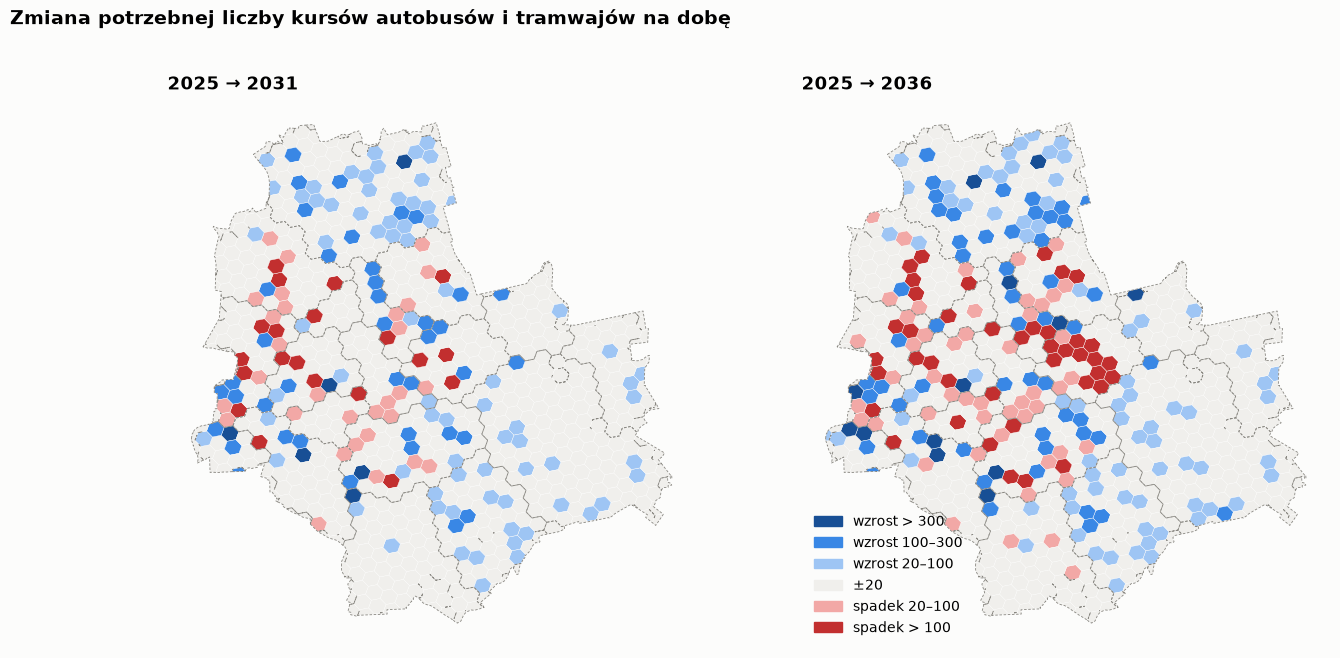

In [9]:
g = hexes.merge(c[["h3", "deficyt_2036", "deficyt_2031"]], on="h3").to_crs(2180)
dz = gpd.read_file("dane/kontury_400m/warszawa_h3_400m_pelna.geojson").dissolve("dzielnica").to_crs(2180)
bins = [-1e9, -100, -20, 20, 100, 300, 1e9]
cols = ["#c22f2f", "#f2a8a6", "#f0efec", "#9ec5f4", "#3987e5", "#184f95"]
labs = ["spadek > 100", "spadek 20–100", "±20", "wzrost 20–100", "wzrost 100–300", "wzrost > 300"]
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, col, title in [(axes[0], "deficyt_2031", "2025 → 2031"), (axes[1], "deficyt_2036", "2025 → 2036")]:
    k = pd.cut(g[col], bins, labels=False)
    g.plot(ax=ax, color=[cols[int(i)] for i in k], edgecolor=SURF, linewidth=0.3)
    dz.boundary.plot(ax=ax, color=MUTED, linewidth=0.6, linestyle=(0, (3, 2)))
    ax.set_axis_off(); ax.set_title(title)
fig.suptitle("Zmiana potrzebnej liczby kursów autobusów i tramwajów na dobę", x=0.02, ha="left", fontweight="bold", fontsize=14)
axes[1].legend(handles=[Patch(color=cc, label=l) for cc, l in zip(cols, labs)][::-1], frameon=False, loc="lower left")
plt.show()

In [10]:
dzielnice = c.groupby("dzielnica").agg(kursy_dzis=(TARGET, "sum"), wzrost_potrzeby_2031=("deficyt_2031", "sum"),
                                       wzrost_potrzeby_2036=("deficyt_2036", "sum"))
dzielnice["wzrost_2036_%"] = (100 * dzielnice["wzrost_potrzeby_2036"] / dzielnice["kursy_dzis"]).round(1)
dzielnice.sort_values("wzrost_2036_%", ascending=False).round(0)

,kursy_dzis,wzrost_potrzeby_2031,wzrost_potrzeby_2036,wzrost_2036_%
dzielnica,,,,
Ursus,8720.0,968.0,1789.0,20.0
Wilanów,11694.0,1063.0,1434.0,12.0
Białołęka,45991.0,3293.0,4982.0,11.0
Wawer,27740.0,1064.0,1526.0,6.0
Rembertów,8877.0,160.0,430.0,5.0
Praga-Północ,26129.0,841.0,1191.0,5.0
Włochy,21008.0,613.0,861.0,4.0
Wesoła,7278.0,143.0,180.0,2.0
Ursynów,25294.0,504.0,535.0,2.0


## 6. Zapis

In [11]:
out = c[["h3", "dzielnica", TARGET, "kursy_szczyt_bus_tram", "potrzeba_dzis", "roznica_dzis",
         "potrzeba_model_dzis", "potrzeba_2031", "potrzeba_2036", "deficyt_2031", "deficyt_2036", "metro_nowe_2036"]].rename(columns={TARGET: "kursy_dzis"})
out.to_csv("dane/potrzeba_komunikacji.csv", index=False, encoding="utf-8")
print("zapisano dane/potrzeba_komunikacji.csv", out.shape)

zapisano dane/potrzeba_komunikacji.csv (848, 12)


## Podsumowanie i ograniczenia
* Model przewiduje liczbę kursów z cech klastra; jakość sprawdzona na dzielnicach, których model nie widział (tabela w sekcji 2).
* **Deficyt** to przyrost potrzeby kursów do 2031/2036 z powodu nowych mieszkańców i nowego metra — gotowy do wzoru scoringu zespołu (zamiast ręcznego „obsługa ZTM”).
* Ograniczenia: uczymy się z dzisiejszej sieci (jej niedoskonałości są „normą”); miejsca pracy to przybliżenie z OSM i zakładamy, że do 2036 się nie zmienią; rozkład z jednego dnia roboczego; efekt nowego metra (−25% w 800 m) to założenie, nie wynik modelu.